# Apartment Rental Price Prediction

Predict monthly rent with the supplied training data. We compare Linear Regression, Decision Tree, Random Forest, and Gradient Boosting, plus optional models. The same shuffled five folds and dollar RMSE guide comparison and tuning. `ID` is never a predictor. Run every cell from top to bottom; the final cell writes `predictions.csv` to the repository root.

## Imports and reproducibility

In [1]:
# First draft for apartment predictor

# 1. Import packages
from IPython.display import display
from pathlib import Path

# Core data handling
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings('ignore')

# Preprocessing + pipelines
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Validation tools
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import KFold, cross_validate, GridSearchCV

# Regression models
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LinearRegression, SGDRegressor   # SGDRegressor = linear regression fit by gradient descent
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor,
                              HistGradientBoostingRegressor)
import xgboost
from xgboost import XGBRegressor   # extra gradient boosting model (XGBoost library)

# Reproducibility: every random process uses this seed
RANDOM_STATE = 42
PROJECT_ROOT = (Path(__file__).resolve().parent if '__file__' in globals()
                else Path.cwd().parent if Path.cwd().name == 'models' else Path.cwd())

pd.set_option('display.max_columns', None)   # show every column of the comparison table in the terminal
pd.set_option('display.width', 250)



## Explore the data

Train shape: (7398, 10) | Test shape: (2467, 9)


,ID,price,bathrooms,bedrooms,square_feet,latitude,longitude,category,has_photo,state
0,2,925,1.0,0,116,47.6160,-122.3275,housing/rent/apartment,Thumbnail,WA
1,3,2475,1.0,0,130,40.7629,-73.9885,housing/rent/apartment,Thumbnail,NY
2,5,1695,1.0,0,190,37.7599,-122.4379,housing/rent/apartment,Thumbnail,CA
3,6,1560,1.0,1,200,35.0847,-77.0609,housing/rent/apartment,Thumbnail,NC
4,7,1560,1.0,1,200,35.0960,-77.0272,housing/rent/apartment,Thumbnail,NC


<class 'pandas.DataFrame'>
RangeIndex: 7398 entries, 0 to 7397
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   ID           7398 non-null   int64  
 1   price        7398 non-null   int64  
 2   bathrooms    7398 non-null   float64
 3   bedrooms     7398 non-null   int64  
 4   square_feet  7398 non-null   int64  
 5   latitude     7398 non-null   float64
 6   longitude    7398 non-null   float64
 7   category     7398 non-null   str    
 8   has_photo    7398 non-null   str    
 9   state        7398 non-null   str    
dtypes: float64(3), int64(4), str(3)
memory usage: 811.5 KB


,count,mean,std,min,25%,50%,75%,max
price,7398.0,1462.805488,821.583589,200.0000,949.0000,1273.5000,1695.0000,8800.0000
bathrooms,7398.0,1.379832,0.602894,1.0000,1.0000,1.0000,2.0000,7.0000
bedrooms,7398.0,1.743850,0.936658,0.0000,1.0000,2.0000,2.0000,9.0000
square_feet,7398.0,940.935253,502.246805,116.0000,650.0000,807.5000,1100.0000,5921.0000
latitude,7398.0,37.647724,5.517342,21.3155,33.6047,38.7701,41.3498,61.5940
longitude,7398.0,-94.407727,15.722082,-158.0221,-98.5290,-93.6516,-81.6437,-70.3461


Missing values (train): 0
Missing values (test):  0

category: 3 unique values
category
housing/rent/apartment     7395
housing/rent/home             2
housing/rent/short_term       1
Name: count, dtype: int64

has_photo: 3 unique values
has_photo
Thumbnail    6566
Yes           693
No            139
Name: count, dtype: int64

state: 50 unique values
state
TX    1327
CA     688
WA     375
MD     341
NC     340
NJ     294
GA     271
FL     249
OH     232
CO     230
Name: count, dtype: int64

States in test but not in train: {'WY'}


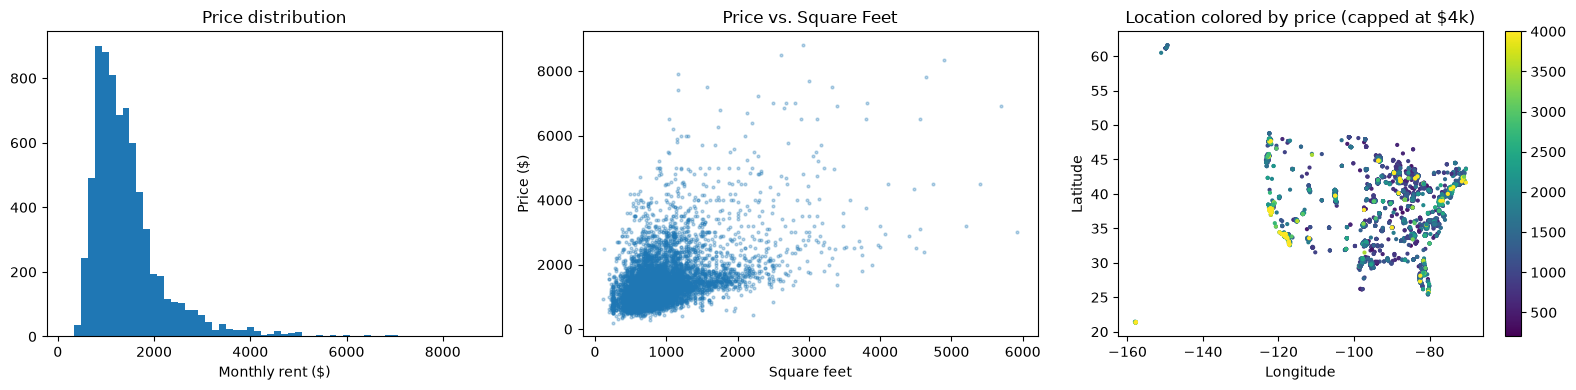

,price
price,1.000000
square_feet,0.484285
bathrooms,0.444624
bedrooms,0.358349
latitude,0.039075
longitude,-0.192189


,count,median
state,,
CA,688,2325.0
MA,119,2274.0
DC,62,1966.0
NJ,294,1811.0
WA,375,1675.0
NY,56,1500.5
MD,341,1476.0
VA,149,1424.0
FL,249,1350.0


In [2]:
# 2. Load and inspect

# Load both datasets
df_train = pd.read_csv(PROJECT_ROOT / 'datasets' / 'challenge1_train.csv')
df_test  = pd.read_csv(PROJECT_ROOT / 'datasets' / 'challenge1_test.csv')   # used ONLY for final predictions

print('Train shape:', df_train.shape, '| Test shape:', df_test.shape)
display(df_train.head())
df_train.info()

# Quick peek at the numeric stats (skipping ID since it's just a useless tag)
display(df_train.drop(columns='ID').describe().T)

# Supposedly the data is clean, but let's double-check that no missing values snuck in[cite: 1, 2]
print('Missing values (train):', df_train.isna().sum().sum())
print('Missing values (test): ', df_test.isna().sum().sum())

# Let's see what's going on with the text categories[cite: 1, 2]
for col in ['category', 'has_photo', 'state']:
    print(f"\n{col}: {df_train[col].nunique()} unique values")
    print(df_train[col].value_counts().head(10))

# Catching any sneaky states in the test data that didn't show up during training[cite: 1, 2]
unseen_states = set(df_test['state']) - set(df_train['state'])
print('\nStates in test but not in train:', unseen_states)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# 1. Distribution of price
axes[0].hist(df_train['price'], bins=60)
axes[0].set_title('Price distribution')
axes[0].set_xlabel('Monthly rent ($)')

# 2. Price vs. square feet (size should be a strong driver)
axes[1].scatter(df_train['square_feet'], df_train['price'], s=4, alpha=0.3)
axes[1].set_title('Price vs. Square Feet')
axes[1].set_xlabel('Square feet'); axes[1].set_ylabel('Price ($)')

# 3. Location map colored by price (location should also be a strong driver)
sc = axes[2].scatter(df_train['longitude'], df_train['latitude'],
                     c=np.clip(df_train['price'], 0, 4000), s=4, cmap='viridis')
axes[2].set_title('Location colored by price (capped at $4k)')
axes[2].set_xlabel('Longitude'); axes[2].set_ylabel('Latitude')
plt.colorbar(sc, ax=axes[2])

plt.tight_layout()
plt.show()

# Correlation of numeric features with price
num_preview = ['price', 'bathrooms', 'bedrooms', 'square_feet', 'latitude', 'longitude']
display(df_train[num_preview].corr()[['price']].sort_values('price', ascending=False))

# Median price by state (top 10 most expensive states with at least 30 listings)
state_stats = df_train.groupby('state')['price'].agg(['count', 'median'])
display(state_stats[state_stats['count'] >= 30].sort_values('median', ascending=False).head(10))




## Prepare features and validation

In [3]:
# PREPARE DATA

def add_features(df):
    """Create engineered features. Uses only values within each row,
    so applying it to train and test separately causes no data leakage."""
    df = df.copy()
    df['sqft_per_bed'] = df['square_feet'] / (df['bedrooms'] + 1)   # +1 avoids divide-by-zero for studios
    df['bath_per_bed'] = df['bathrooms'] / (df['bedrooms'] + 1)
    df['total_rooms']  = df['bedrooms'] + df['bathrooms']
    return df

DROP_COLS = ['ID', 'category']

# Adding training predictors and target
X = add_features(df_train.drop(columns=DROP_COLS + ['price']))
y = df_train['price']

# Test predictors (same transformations, no target available -_-)
X_test = add_features(df_test.drop(columns=DROP_COLS))

# Separate dtypes for preprocessing steps
cat_cols = X.select_dtypes(exclude='number').columns.tolist()   # text columns (works for object or string dtype)
num_cols = [c for c in X.columns if c not in cat_cols]

print('Categorical:', cat_cols)

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = 'neg_root_mean_squared_error'   # sklearn maximizes scores, so RMSE is returned as a negative
print('Numeric:    ', num_cols)
print('X shape:', X.shape, '| X_test shape:', X_test.shape)



Categorical: ['has_photo', 'state']
Numeric:     ['bathrooms', 'bedrooms', 'square_feet', 'latitude', 'longitude', 'sqft_per_bed', 'bath_per_bed', 'total_rooms']
X shape: (7398, 10) | X_test shape: (2467, 10)


## Preprocessing and baseline comparison

,Model,Train_RMSE,CV_RMSE,CV_RMSE_std,Time_sec,Gap (CV - Train)
0,Hist Gradient Boost,308.0,415.5,28.5,0.6,107.5
1,Random Forest,162.6,429.2,33.5,4.7,266.6
2,Gradient Boosting,399.7,457.2,26.1,0.8,57.6
3,Linear Regression,518.8,525.4,27.9,2.1,6.6
4,SGD (Gradient Descent),526.3,531.3,30.8,0.1,5.1
5,Decision Tree,40.7,565.8,48.2,1.3,525.1


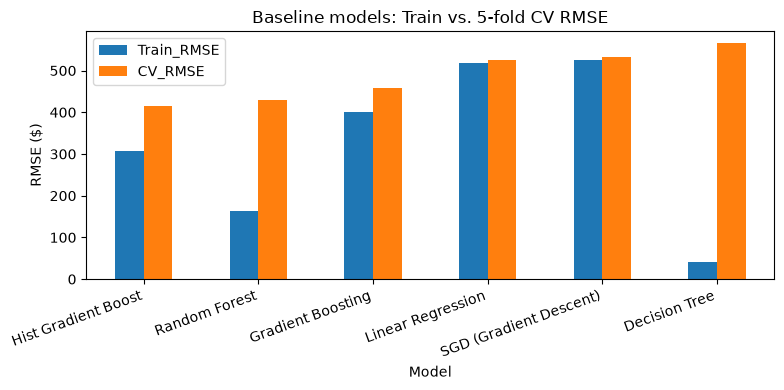

In [4]:
# Defining processes!
def make_preprocess():
    return ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
        ('num', StandardScaler(), num_cols)
    ])

def make_pipe(model):
    """Wrap any regressor into a full preprocess -> model pipeline."""
    return Pipeline([
        ('preprocess', make_preprocess()),
        ('model', model)
    ])
baseline_models = {
    'Linear Regression':   LinearRegression(),
    'Decision Tree':       DecisionTreeRegressor(random_state=RANDOM_STATE),
    'Random Forest':       RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    'Gradient Boosting':   GradientBoostingRegressor(random_state=RANDOM_STATE),
    'SGD (Gradient Descent)': SGDRegressor(max_iter=2000, tol=1e-4, random_state=RANDOM_STATE),   # linear model fit by gradient descent
    'Hist Gradient Boost': HistGradientBoostingRegressor(random_state=RANDOM_STATE),   # extra model
}

def evaluate(name, pipe):
    """Run 5-fold CV and return mean train/validation RMSE and fit time."""
    t0 = time.perf_counter()
    res = cross_validate(pipe, X, y, cv=cv, scoring=SCORING, return_train_score=True, n_jobs=-1)
    return {
        'Model':          name,
        'Train_RMSE':     -res['train_score'].mean(),
        'CV_RMSE':        -res['test_score'].mean(),
        'CV_RMSE_std':    res['test_score'].std(),
        'Time_sec':       time.perf_counter() - t0,
    }

baseline_results = [evaluate(name, make_pipe(m)) for name, m in baseline_models.items()]
baseline_df = pd.DataFrame(baseline_results).sort_values('CV_RMSE').reset_index(drop=True)
baseline_df['Gap (CV - Train)'] = baseline_df['CV_RMSE'] - baseline_df['Train_RMSE']   # overfitting indicator
# baseline_df.round(1)
display(baseline_df.round(1)) # new display line

# Visual comparison of train vs. validation RMSE

ax = baseline_df.set_index('Model')[['Train_RMSE', 'CV_RMSE']].plot(kind='bar', figsize=(8, 4))
ax.set_ylabel('RMSE ($)')
ax.set_title('Baseline models: Train vs. 5-fold CV RMSE')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()



## Tune selected models with Grid Search

In [5]:
# 7 & 8. Improve the models with Grid Search and select final model

# Hyperparameter grids for each model we tune.
# 'model__' prefix = the parameter belongs to the 'model' step of the pipeline.
# Every grid uses the SAME 5 folds (cv) as the baseline, so results are comparable.
param_grids = {
    # Gradient descent: tune regularization strength/type and the learning rate schedule
    'SGD (Gradient Descent)': (
        SGDRegressor(max_iter=2000, tol=1e-4, random_state=RANDOM_STATE),
        {'model__alpha':         [1e-4, 1e-3, 1e-2],        # regularization strength
         'model__penalty':       ['l2', 'elasticnet'],      # type of regularization
         'model__learning_rate': ['adaptive'],              # shrink step size when loss stops improving
         'model__eta0':          [0.01]}                    # starting step size
    ),
    # Decision Tree: limit depth / leaf size to fight the heavy overfitting seen in the baseline
    'Decision Tree': (
        DecisionTreeRegressor(random_state=RANDOM_STATE),
        {'model__max_depth':        [8, 12, 16, None],
         'model__min_samples_leaf': [1, 5, 10]}
    ),
    # Random Forest: features per split and leaf size
    'Random Forest': (
        RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
        {'model__max_features':     [0.33, 0.5, 1.0],
         'model__min_samples_leaf': [1, 3]}
    ),
    # Gradient Boosting: number of trees, step size, tree depth, row sampling
    'Gradient Boosting': (
        GradientBoostingRegressor(random_state=RANDOM_STATE),
        {'model__n_estimators':  [300, 500],
         'model__learning_rate': [0.05, 0.1],
         'model__max_depth':     [4, 5, 6],
         'model__subsample':     [0.8]}
    ),
    # Hist Gradient Boosting: faster boosting, tune step size, rounds, tree size
    'Hist Gradient Boost': (
        HistGradientBoostingRegressor(random_state=RANDOM_STATE),
        {'model__learning_rate':  [0.05, 0.1],
         'model__max_iter':       [300, 600],
         'model__max_leaf_nodes': [15, 31]}
    ),
    # XGBoost: same ideas as Gradient Boosting plus column sampling
    'XGBoost': (
        XGBRegressor(subsample=0.8, random_state=RANDOM_STATE, n_jobs=1),
        {'model__n_estimators':     [300, 600],
         'model__learning_rate':    [0.03, 0.1],
         'model__max_depth':        [4, 6],
         'model__colsample_bytree': [0.8, 1.0]}
    ),
}

grid_searches = {}   # name -> fitted GridSearchCV (used below to pick the final model)
tuned_rows = []      # one summary row per tuned model

for name, (model, grid) in param_grids.items():
    t0 = time.perf_counter()
    gs = GridSearchCV(make_pipe(model), grid, cv=cv, scoring=SCORING,
                      return_train_score=True, n_jobs=-1, refit=True)   # refit=True -> best model retrained on ALL training data
    gs.fit(X, y)
    grid_searches[name] = gs

    best = gs.best_index_   # row of the best parameter combination in cv_results_
    tuned_rows.append({
        'Model':       name + ' (tuned)',
        'Train_RMSE':  -gs.cv_results_['mean_train_score'][best],
        'CV_RMSE':     -gs.best_score_,
        'CV_RMSE_std': gs.cv_results_['std_test_score'][best],
        'Time_sec':    time.perf_counter() - t0,
        'Best_params': {k.replace('model__', ''): v for k, v in gs.best_params_.items()},
    })
    print(f"{name:24s} best CV RMSE = {-gs.best_score_:8.1f}  ({time.perf_counter() - t0:5.1f}s)  {tuned_rows[-1]['Best_params']}")



SGD (Gradient Descent)   best CV RMSE =    526.4  (  4.5s)  {'alpha': 0.0001, 'eta0': 0.01, 'learning_rate': 'adaptive', 'penalty': 'elasticnet'}


Decision Tree            best CV RMSE =    501.5  (  0.5s)  {'max_depth': 16, 'min_samples_leaf': 10}


/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.

/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.

/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.

...

/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.

Random Forest            best CV RMSE =    425.3  ( 14.5s)  {'max_features': 0.5, 'min_samples_leaf': 3}


Gradient Boosting        best CV RMSE =    401.3  ( 43.1s)  {'learning_rate': 0.05, 'max_depth': 6, 'n_estimators': 500, 'subsample': 0.8}


Hist Gradient Boost      best CV RMSE =    409.4  ( 12.6s)  {'learning_rate': 0.1, 'max_iter': 600, 'max_leaf_nodes': 15}


XGBoost                  best CV RMSE =    406.5  (  5.9s)  {'colsample_bytree': 0.8, 'learning_rate': 0.03, 'max_depth': 6, 'n_estimators': 600}


## Compare models and fit the winner

In [6]:
# Full comparison table: baseline vs. tuned, sorted by validation RMSE
comparison_df = (pd.concat([baseline_df.drop(columns='Gap (CV - Train)'), pd.DataFrame(tuned_rows)], ignore_index=True)
                   .sort_values('CV_RMSE').reset_index(drop=True))
comparison_df['Gap (CV - Train)'] = comparison_df['CV_RMSE'] - comparison_df['Train_RMSE']   # overfitting indicator
pd.set_option('display.max_colwidth', 120)
display(comparison_df.round(1))

# Include baseline candidates: tuning is not guaranteed to improve them.
candidate_models = {name: make_pipe(model) for name, model in baseline_models.items()}
candidate_models.update({name + ' (tuned)': search.best_estimator_
                         for name, search in grid_searches.items()})
best_row = comparison_df.iloc[0]
best_name = best_row['Model']
final_model = candidate_models[best_name]
fit_start = time.perf_counter()
final_model.fit(X, y)  # Fit the selected model on all labeled rows.
final_fit_sec = time.perf_counter() - fit_start 

print('Final model:   ', best_name)
if best_name.endswith(' (tuned)'):
    print('Best params:   ', grid_searches[best_name.removesuffix(' (tuned)')].best_params_)
else:
    print('Best params:    baseline settings')
print(f"CV RMSE:        {best_row['CV_RMSE']:.1f}")
print(f"Avg rent:       {y.mean():.1f}  (RMSE as % of mean rent: {best_row['CV_RMSE'] / y.mean():.1%})")



,Model,Train_RMSE,CV_RMSE,CV_RMSE_std,Time_sec,Best_params,Gap (CV - Train)
0,Gradient Boosting (tuned),176.4,401.3,34.4,43.1,"{'learning_rate': 0.05, 'max_depth': 6, 'n_estimators': 500, 'subsample': 0.8}",224.8
1,XGBoost (tuned),228.0,406.5,30.2,5.9,"{'colsample_bytree': 0.8, 'learning_rate': 0.03, 'max_depth': 6, 'n_estimators': 600}",178.4
2,Hist Gradient Boost (tuned),243.7,409.4,30.5,12.6,"{'learning_rate': 0.1, 'max_iter': 600, 'max_leaf_nodes': 15}",165.7
3,Hist Gradient Boost,308.0,415.5,28.5,0.6,NaN,107.5
4,Random Forest (tuned),287.1,425.3,30.4,14.5,"{'max_features': 0.5, 'min_samples_leaf': 3}",138.2
5,Random Forest,162.6,429.2,33.5,4.7,NaN,266.6
6,Gradient Boosting,399.7,457.2,26.1,0.8,NaN,57.6
7,Decision Tree (tuned),395.8,501.5,30.7,0.5,"{'max_depth': 16, 'min_samples_leaf': 10}",105.7
8,Linear Regression,518.8,525.4,27.9,2.1,NaN,6.6
9,SGD (Gradient Descent) (tuned),520.7,526.4,29.2,4.5,"{'alpha': 0.0001, 'eta0': 0.01, 'learning_rate': 'adaptive', 'penalty': 'elasticnet'}",5.8


Final model:    Gradient Boosting (tuned)
Best params:    {'model__learning_rate': 0.05, 'model__max_depth': 6, 'model__n_estimators': 500, 'model__subsample': 0.8}
CV RMSE:        401.3
Avg rent:       1462.8  (RMSE as % of mean rent: 27.4%)


## Inspect feature influence

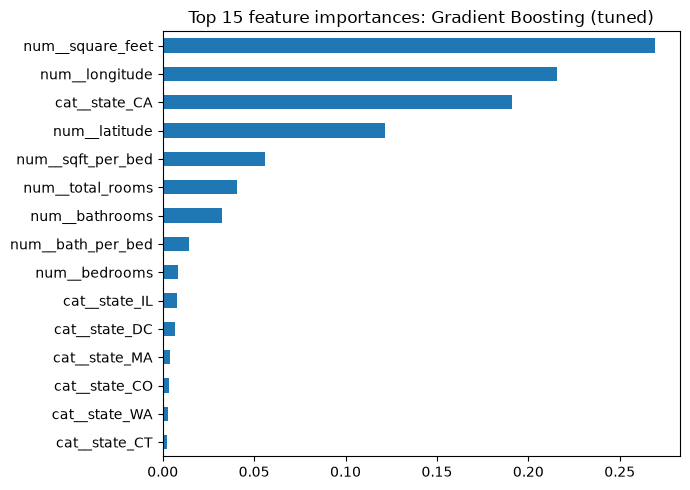

In [7]:
# Feature importance for tree-based final models (helps explain the model)
model_step = final_model.named_steps['model']
feat_names = final_model.named_steps['preprocess'].get_feature_names_out()
top_features = None
if hasattr(model_step, 'feature_importances_'):
    imp = (pd.Series(model_step.feature_importances_, index=feat_names)
             .sort_values(ascending=False).head(15))
    top_features = imp.head(5)
    imp.sort_values().plot(kind='barh', figsize=(7, 5), title=f'Top 15 feature importances: {best_name}')
    plt.tight_layout(); plt.show()
elif hasattr(model_step, 'coef_'):
    coefs = pd.Series(model_step.coef_, index=feat_names)   # linear models: coefficients on scaled features
    top_features = coefs.abs().sort_values(ascending=False).head(5)
else:
    print(f'{best_name} has no built-in feature_importances_ (use permutation importance during fine-tuning).')
 


## Justify the final model

In [8]:
# Model selection justification
# Printed (not just written in comments) so the reasoning is visible in the output.
def lookup(model_name):
    """Return the comparison_df row for a model, or None if it was not run."""
    rows = comparison_df[comparison_df['Model'] == model_name]
    return rows.iloc[0] if len(rows) else None
 
runner_up = comparison_df.iloc[1]
lin_row   = lookup('Linear Regression')
tree_row  = lookup('Decision Tree')
gap       = best_row['CV_RMSE'] - best_row['Train_RMSE']
base_name = best_name.removesuffix(' (tuned)')
 
# Model complexity: report the size-related settings the final model actually uses
size_keys = ['n_estimators', 'max_iter', 'max_depth', 'max_leaf_nodes', 'min_samples_leaf', 'learning_rate']
size_info = {k: v for k, v in model_step.get_params().items() if k in size_keys and v is not None}
 
# Interpretability notes
interpretability_notes = {
    'Linear Regression':      'high: coefficients describe transformed features, although correlated features complicate interpretation',
    'SGD (Gradient Descent)': 'high: coefficients describe transformed features, although correlated features complicate interpretation',
    'Decision Tree':          'high: the splits can be read as if/then rules',
    'Random Forest':          'moderate: an average of many trees; explained through feature importances',
    'Gradient Boosting':      'moderate: a sum of many small trees; explained through feature importances',
    'Hist Gradient Boost':    'moderate: a sum of many small trees; no built-in importances (use permutation importance)',
    'XGBoost':                'moderate: a sum of many small trees; explained through feature importances',
}
 
print('\n' + '=' * 78)
print(f'MODEL SELECTION JUSTIFICATION: {best_name}')
print('=' * 78)
 
print('\n1. Validation performance')
print(f"   - Lowest 5-fold CV RMSE of all {len(comparison_df)} model versions: "
      f"${best_row['CV_RMSE']:.1f} (+/- {best_row['CV_RMSE_std']:.1f} across folds).")
print(f"   - Runner-up: {runner_up['Model']} at ${runner_up['CV_RMSE']:.1f} "
      f"({runner_up['CV_RMSE'] - best_row['CV_RMSE']:.1f} higher).")
if runner_up['CV_RMSE'] - best_row['CV_RMSE'] < best_row['CV_RMSE_std']:
    print('     The gap is smaller than one fold standard deviation, so the top models are close;')
    print('     we keep the lowest mean CV RMSE as the deciding factor because RMSE is the competition metric.')
if lin_row is not None:
    print(f"   - {lin_row['CV_RMSE'] - best_row['CV_RMSE']:.1f} lower than the Linear Regression baseline "
          f"(${lin_row['CV_RMSE']:.1f}).")
 
print('\n2. Overfitting / underfitting')
print(f"   - Train RMSE ${best_row['Train_RMSE']:.1f} vs CV RMSE ${best_row['CV_RMSE']:.1f} "
      f"(gap ${gap:.1f}, {gap / best_row['CV_RMSE']:.0%} of CV RMSE).")
if gap / best_row['CV_RMSE'] > 0.30:
    print('   - This is a noticeable overfitting tendency (the model fits training rows much more tightly than new ones).')
    print('     The held-out CV RMSE includes this effect and remains the lowest among the candidates.')
else:
    print('   - The gap is small, so the model is not overfitting much, and its CV RMSE is the lowest of all models.')
if tree_row is not None and tree_row['Model'] != best_name:
    print(f"   - For contrast, the untuned Decision Tree overfits (train ${tree_row['Train_RMSE']:.1f} "
          f"vs CV ${tree_row['CV_RMSE']:.1f}).")
if lin_row is not None and lin_row['Model'] != best_name:
    print(f"   - Linear Regression underfits (train ${lin_row['Train_RMSE']:.1f} and CV ${lin_row['CV_RMSE']:.1f} "
          f"are close but both high): rent vs. location is not linear.")
 
print('\n3. Model complexity')
print(f'   - Settings: {size_info}')
if isinstance(model_step, (LinearRegression, SGDRegressor)):
    print('   - A linear model with one coefficient per transformed feature.')
elif isinstance(model_step, DecisionTreeRegressor):
    print(f'   - One tree with {model_step.get_n_leaves()} leaves.')
else:
    print('   - An ensemble of trees; its added complexity is justified by the lowest validation RMSE.')
 
print('\n4. Computational requirements')
print(f"   - Search/CV time for this model: {best_row['Time_sec']:.1f}s; final refit on all {len(X):,} rows: {final_fit_sec:.1f}s.")
print('   - Prediction on the test set is near-instant, so the cost is acceptable for this dataset size.')
 
print('\n5. Interpretability')
print(f"   - {interpretability_notes.get(base_name, 'see feature importances')}.")
if top_features is not None:
    print('   - Largest feature importance or coefficient magnitudes (not causal effects): ' +
          ', '.join(f"{n.replace('num__', '').replace('cat__', '')} ({v:.2f})" for n, v in top_features.items()))
 
print('\nConclusion: we expect this model to generalize best to unseen apartments because it has the lowest')
print('cross-validated RMSE (which already accounts for its overfitting), with acceptable cost and explainability.')
print('=' * 78 + '\n')
 



MODEL SELECTION JUSTIFICATION: Gradient Boosting (tuned)

1. Validation performance
   - Lowest 5-fold CV RMSE of all 12 model versions: $401.3 (+/- 34.4 across folds).
   - Runner-up: XGBoost (tuned) at $406.5 (5.2 higher).
     The gap is smaller than one fold standard deviation, so the top models are close;
     we keep the lowest mean CV RMSE as the deciding factor because RMSE is the competition metric.
   - 124.1 lower than the Linear Regression baseline ($525.4).

2. Overfitting / underfitting
   - Train RMSE $176.4 vs CV RMSE $401.3 (gap $224.8, 56% of CV RMSE).
   - This is a noticeable overfitting tendency (the model fits training rows much more tightly than new ones).
     The held-out CV RMSE includes this effect and remains the lowest among the candidates.
   - For contrast, the untuned Decision Tree overfits (train $40.7 vs CV $565.8).
   - Linear Regression underfits (train $518.8 and CV $525.4 are close but both high): rent vs. location is not linear.

3. Model complex

## Generate and verify predictions

In [9]:
# Generate predictions for the test set
test_pred = final_model.predict(X_test)

# Keep the test IDs in their original order, one row per test observation
predictions = pd.DataFrame({'ID': df_test['ID'].values, 'price': test_pred})
output_path = PROJECT_ROOT / 'predictions.csv'
predictions.to_csv(output_path, index=False)

# checks on the SAVED file: correct columns, every test ID exactly once, valid prices
saved = pd.read_csv(output_path)
assert list(saved.columns) == ['ID', 'price'], 'predictions.csv must have exactly the columns ID, price'
assert len(saved) == len(df_test), 'one prediction per test row'
assert saved['ID'].equals(df_test['ID']), 'IDs must match challenge1_test.csv (same IDs, same order)'
assert saved['ID'].is_unique, 'no duplicate IDs'
assert np.isfinite(saved['price']).all(), 'all predicted prices must be finite'
 
print(f"Saved predictions.csv: {len(saved)} rows (all {len(df_test)} test IDs), columns {list(saved.columns)}")
print('Location:', output_path)
display(saved['price'].describe().round(1).to_frame().T)
display(saved.head())


Saved predictions.csv: 2467 rows (all 2467 test IDs), columns ['ID', 'price']
Location: /Users/borismino/.codex/worktrees/draft-syntax-fix/CAI4105_2026_FALL_TEAM_1/predictions.csv


,count,mean,std,min,25%,50%,75%,max
price,2467.0,1475.7,766.6,492.5,1013.8,1255.5,1665.3,7462.8


,ID,price
0,1,1607.749475
1,4,1820.862541
2,9,852.044403
3,11,770.938119
4,13,742.755144
